# A1.1 — PathMNIST và kiểm tra pipeline
Bùi Tiến Đức — MSSV 2680018

Notebook riêng cho A1.1. Chỉ chạy EDA, DataLoader và phép kiểm tra 20 batch train/10 batch validation. Không huấn luyện đầy đủ và không đánh giá test. Output được xóa có chủ đích; minh chứng đã chạy nằm trong results/vit_pipeline_check.json.

Code bổ sung của sinh viên; kiến trúc dùng Transformers. Notebook tác giả và LICENSE được giữ riêng tại MedMNIST-ViT-main/.


## 1 Thống kê dữ liệu và hình EDA


Đã đọc: C:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\data\pathmnist.npz


,class_id,class_name,train,val,test
0,0,Adipose,9366,1041,1338
1,1,Background,9509,1057,847
2,2,Debris,10360,1152,339
3,3,Lymphocytes,10401,1156,634
4,4,Mucus,8006,890,1035
5,5,Smooth muscle,12182,1354,592
6,6,Normal colon mucosa,7886,877,741
7,7,Cancer-associated stroma,9401,1045,421
8,8,Colorectal adenocarcinoma epithelium,12885,1432,1233


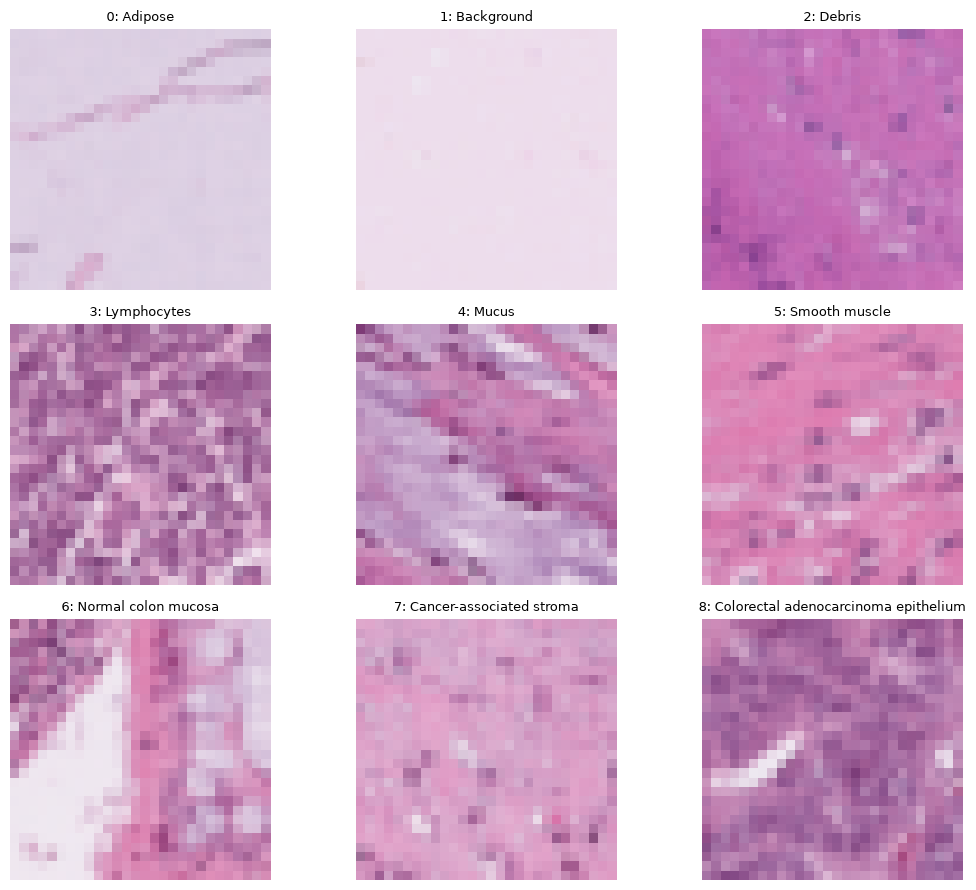

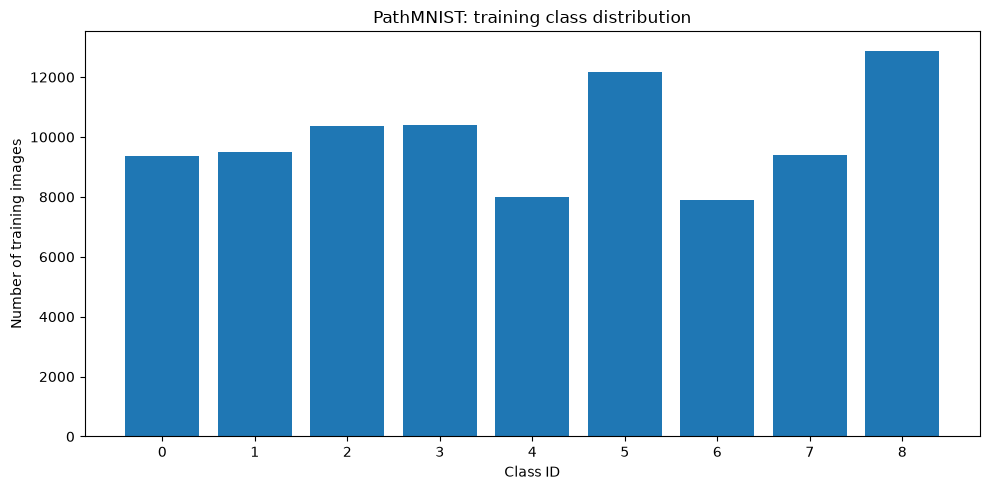

Đã lưu tại: C:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\results


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Khai báo đường dẫn và đọc dữ liệu trước
# Chạy từ thư mục A1 hoặc thư mục gốc repo.
_candidates = [Path.cwd() / "data/pathmnist.npz",
               Path.cwd() / "A1/data/pathmnist.npz"]
data_path = next((p.resolve() for p in _candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Đặt pathmnist.npz tại A1/data; chạy notebook từ A1 hoặc gốc repo.")

if not data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy: {data_path}")

data = np.load(data_path, allow_pickle=False)
print("Đã đọc:", data_path)

# 2. Tạo thư mục lưu kết quả
results_dir = data_path.parent.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

class_names = [
    "Adipose", "Background", "Debris",
    "Lymphocytes", "Mucus", "Smooth muscle",
    "Normal colon mucosa", "Cancer-associated stroma",
    "Colorectal adenocarcinoma epithelium"
]

# 3. Thống kê số ảnh mỗi lớp
stats = pd.DataFrame({
    "class_id": range(9),
    "class_name": class_names
})

for split in ["train", "val", "test"]:
    labels = data[f"{split}_labels"].reshape(-1)
    stats[split] = [
        int((labels == class_id).sum())
        for class_id in range(9)
    ]

stats.to_csv(
    results_dir / "class_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)
display(stats)

# 4. Hiển thị một ảnh train đại diện mỗi lớp
images = data["train_images"]
labels = data["train_labels"].reshape(-1)

fig, axes = plt.subplots(3, 3, figsize=(11, 9))

for class_id, ax in enumerate(axes.flat):
    indices = np.flatnonzero(labels == class_id)
    if len(indices):
        ax.imshow(images[indices[0]])

    ax.set_title(f"{class_id}: {class_names[class_id]}", fontsize=9)
    ax.axis("off")

fig.tight_layout()
fig.savefig(results_dir / "sample_images.png", dpi=200)
plt.show()
plt.close(fig)

# 5. Biểu đồ phân bố lớp trên tập train
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(stats["class_id"].astype(str), stats["train"])
ax.set_xlabel("Class ID")
ax.set_ylabel("Number of training images")
ax.set_title("PathMNIST: training class distribution")

fig.tight_layout()
fig.savefig(results_dir / "train_class_distribution.png", dpi=200)
plt.show()
plt.close(fig)

data.close()
print("Đã lưu tại:", results_dir)


## 2 Dataset và DataLoader
Normalization 0,5 trong ô này dùng cho phép kiểm tra ViT; chưa phải preprocessing của ResNet-18.


In [2]:
import random
random.seed(42)
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

np.random.seed(42)
torch.manual_seed(42)

# 1. Đọc dữ liệu
# Chạy từ thư mục A1 hoặc thư mục gốc repo.
_candidates = [Path.cwd() / "data/pathmnist.npz",
               Path.cwd() / "A1/data/pathmnist.npz"]
data_path = next((p.resolve() for p in _candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Đặt pathmnist.npz tại A1/data; chạy notebook từ A1 hoặc gốc repo.")

if not data_path.is_file():
    raise FileNotFoundError(data_path)

# Cấu hình tiền xử lý chung cho phép kiểm tra pipeline
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# 2. Dataset: resize từng ảnh khi cần, không resize cả tập vào RAM
class PathMNISTDataset(Dataset):
    def __init__(self, npz_path, split, transform):
        with np.load(npz_path, allow_pickle=False) as archive:
            self.images = archive[f"{split}_images"]
            self.labels = archive[f"{split}_labels"].reshape(-1)

        self.transform = transform

        assert len(self.images) == len(self.labels)
        assert self.labels.min() >= 0
        assert self.labels.max() <= 8

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index]).convert("RGB")
        image = self.transform(image)
        label = torch.tensor(int(self.labels[index]), dtype=torch.long)
        return image, label

# 3. Tạo tập train/validation
train_dataset = PathMNISTDataset(
    data_path, "train", train_transform
)
val_dataset = PathMNISTDataset(
    data_path, "val", val_transform
)

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# 4. Kiểm tra một batch
images, labels = next(iter(train_loader))

assert images.shape == (2, 3, 224, 224)
assert labels.dtype == torch.long
assert torch.isfinite(images).all()

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Batch ảnh:", images.shape)
print("Batch nhãn:", labels)
print("Kiểu nhãn:", labels.dtype)
print("DataLoader: OK")



Train: 89996
Validation: 10004
Batch ảnh: torch.Size([2, 3, 224, 224])
Batch nhãn: tensor([3, 8])
Kiểu nhãn: torch.int64
DataLoader: OK


## 3 Kiểm tra ViT trên dữ liệu thật
Cần Internet tải checkpoint lần đầu. Có cập nhật trọng số trên 40 ảnh, không phải thí nghiệm chính. Chạy lại sẽ ghi đè file results/vit_pipeline_check.json; bản đã nộp có trong lịch sử Git.


In [3]:
import time
import json
import torch
from itertools import islice
from pathlib import Path
from transformers import ViTForImageClassification

if not torch.cuda.is_available():
    raise RuntimeError("Chưa nhận GPU.")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device("cuda")

model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=9,
    ignore_mismatched_sizes=True
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
scaler = torch.amp.GradScaler("cuda")

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start = time.perf_counter()

# 1. Train thử 20 batch
model.train()
train_loss_sum = 0.0
train_samples = 0
train_steps = 0

for images, labels in islice(train_loader, 20):
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        loss = model(pixel_values=images, labels=labels).loss

    if not torch.isfinite(loss):
        raise RuntimeError("Loss không hữu hạn.")

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    n = labels.size(0)
    train_loss_sum += loss.item() * n
    train_samples += n
    train_steps += 1

    print(f"Train batch {train_steps:02d}/20 | loss={loss.item():.4f}")

# 2. Validation thử 10 batch, không cập nhật trọng số
model.eval()
val_loss_sum = 0.0
val_correct = 0
val_samples = 0

with torch.inference_mode():
    for images, labels in islice(val_loader, 10):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(pixel_values=images, labels=labels)

        if not torch.isfinite(outputs.loss):
            raise RuntimeError("Validation loss không hữu hạn.")

        n = labels.size(0)
        val_loss_sum += outputs.loss.item() * n
        val_correct += (outputs.logits.argmax(1) == labels).sum().item()
        val_samples += n

torch.cuda.synchronize()

summary = {
    "purpose": "pipeline_check_only",
    "train_batches": train_steps,
    "train_samples": train_samples,
    "validation_samples": val_samples,
    "train_loss": train_loss_sum / train_samples,
    "validation_loss": val_loss_sum / val_samples,
    "validation_subset_accuracy": val_correct / val_samples,
    "elapsed_seconds": time.perf_counter() - start,
    "peak_allocated_vram_gb":
        torch.cuda.max_memory_allocated() / 1024**3
}

# 3. Lưu bằng chứng kiểm tra
results_dir = data_path.parent.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

output_path = results_dir / "vit_pipeline_check.json"
output_path.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("\nPIPELINE CHECK: OK")
print(json.dumps(summary, indent=2))
print("Đã lưu:", output_path)


c:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([9]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([9, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Train batch 01/20 | loss=2.2393
Train batch 02/20 | loss=2.5400
Train batch 03/20 | loss=2.9697
Train batch 04/20 | loss=2.3809
Train batch 05/20 | loss=2.0850
Train batch 06/20 | loss=2.3594
Train batch 07/20 | loss=2.3252
Train batch 08/20 | loss=2.3188
Train batch 09/20 | loss=1.9668
Train batch 10/20 | loss=2.1045
Train batch 11/20 | loss=2.4067
Train batch 12/20 | loss=2.9736
Train batch 13/20 | loss=2.3931
Train batch 14/20 | loss=2.4048
Train batch 15/20 | loss=1.9634
Train batch 16/20 | loss=2.0879
Train batch 17/20 | loss=2.3555
Train batch 18/20 | loss=2.1509
Train batch 19/20 | loss=2.5469
Train batch 20/20 | loss=2.0762

PIPELINE CHECK: OK
{
  "purpose": "pipeline_check_only",
  "train_batches": 20,
  "train_samples": 40,
  "validation_samples": 20,
  "train_loss": 2.332421875,
  "validation_loss": 2.290478515625,
  "validation_subset_accuracy": 0.0,
  "elapsed_seconds": 2.2589793000370264,
  "peak_allocated_vram_gb": 1.6219816207885742
}
Đã lưu: C:\Users\HCMBK\Downloads\De

## Kết thúc A1.1
Không diễn giải accuracy trên 20 ảnh validation là chất lượng mô hình. A1.2 cần triển khai ResNet-18 và đủ các cấu hình, chọn checkpoint trên validation rồi đánh giá test một lần cho cấu hình đã chốt. Detection YOLO được làm riêng.
